# Verificación del entorno

Este notebook comprueba que las dependencias estén disponibles. La exploración del CSV aún está pendiente.

In [3]:
import pandas as pd
import numpy as np
import sklearn
import matplotlib.pyplot as plt

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Entorno Jupyter configurado correctamente")

Pandas: 3.0.6
NumPy: 2.5.4
Scikit-learn: 1.9.1
Entorno Jupyter configurado correctamente


## 1. Importar bibliotecas y localizar el archivo

In [4]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Ubicación del proyecto
PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "dataset"
    / "datos_abiertos_vigilancia_dengue_2000_2024.csv"
)

print("Proyecto:", PROJECT_ROOT)
print("Dataset:", DATA_PATH)
print("¿Existe el archivo?", DATA_PATH.exists())

Proyecto: D:\UNSCH\IA I\Trabajo Final\isolation-forest-dengue-peru
Dataset: D:\UNSCH\IA I\Trabajo Final\isolation-forest-dengue-peru\data\dataset\datos_abiertos_vigilancia_dengue_2000_2024.csv
¿Existe el archivo? True


## 2. Cargar el dataset

In [6]:
from pathlib import Path
import pandas as pd

NOMBRE_CSV = "datos_abiertos_vigilancia_dengue_2000_2024.csv"
PROJECT_ROOT = next(
    (
        carpeta
        for carpeta in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
        if (carpeta / "data" / "dataset" / NOMBRE_CSV).is_file()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        f"No se encontró data/dataset/{NOMBRE_CSV}. "
        "Coloca allí el CSV y ejecuta esta celda desde el proyecto."
    )

DATA_PATH = PROJECT_ROOT / "data" / "dataset" / NOMBRE_CSV

df = pd.read_csv(
    DATA_PATH,
    sep=";",
    encoding="utf-8-sig",
    low_memory=False,
    dtype={"diresa": "string", "localidad": "string", "ubigeo": "string", "localcod": "string"},
)

print("Archivo cargado:", DATA_PATH.name)
print(f"Filas: {df.shape[0]:,}")
print(f"Columnas: {df.shape[1]}")

display(df.head())

Archivo cargado: datos_abiertos_vigilancia_dengue_2000_2024.csv
Filas: 1,029,421
Columnas: 14


,departamento,provincia,distrito,localidad,enfermedad,ano,semana,diagnostic,diresa,ubigeo,localcod,edad,tipo_edad,sexo
0,LORETO,ALTO AMAZONAS,YURIMAGUAS,000101,DENGUE SIN SIGNOS DE ALARMA,2000,1,A97.0,16,160201,<NA>,58,A,M
1,LORETO,ALTO AMAZONAS,YURIMAGUAS,000101,DENGUE SIN SIGNOS DE ALARMA,2000,1,A97.0,16,160201,<NA>,44,A,F
2,LORETO,ALTO AMAZONAS,YURIMAGUAS,BARRIO MORALILLOS,DENGUE SIN SIGNOS DE ALARMA,2000,1,A97.0,16,160201,<NA>,21,A,F
3,LORETO,MAYNAS,IQUITOS,005902,DENGUE SIN SIGNOS DE ALARMA,2000,1,A97.0,16,160101,<NA>,74,A,M
4,LORETO,MAYNAS,IQUITOS,CARDOZO,DENGUE SIN SIGNOS DE ALARMA,2000,1,A97.0,16,160101,<NA>,42,A,F


## 3. Inspeccionar los datos reales

In [7]:
print("COLUMNAS DEL DATASET")
print(df.columns.tolist())

print("\nINFORMACIÓN GENERAL")
df.info()

print("\nVALORES NULOS")
display(df.isnull().sum().to_frame("Nulos"))

print("\nPRIMEROS REGISTROS")
display(df.head(10))

COLUMNAS DEL DATASET
['departamento', 'provincia', 'distrito', 'localidad', 'enfermedad', 'ano', 'semana', 'diagnostic', 'diresa', 'ubigeo', 'localcod', 'edad', 'tipo_edad', 'sexo']

INFORMACIÓN GENERAL
<class 'pandas.DataFrame'>
RangeIndex: 1029421 entries, 0 to 1029420
Data columns (total 14 columns):
 #   Column        Non-Null Count    Dtype 
---  ------        --------------    ----- 
 0   departamento  1029421 non-null  str   
 1   provincia     1029421 non-null  str   
 2   distrito      1029421 non-null  str   
 3   localidad     906823 non-null   string
 4   enfermedad    1029421 non-null  str   
 5   ano           1029421 non-null  int64 
 6   semana        1029421 non-null  int64 
 7   diagnostic    1029421 non-null  str   
 8   diresa        1029398 non-null  string
 9   ubigeo        1029421 non-null  string
 10  localcod      880780 non-null   string
 11  edad          1029421 non-null  int64 
 12  tipo_edad     1029421 non-null  str   
 13  sexo          1029421 non-null

,Nulos
departamento,0
provincia,0
distrito,0
localidad,122598
enfermedad,0
ano,0
semana,0
diagnostic,0
diresa,23
ubigeo,0



PRIMEROS REGISTROS


,departamento,provincia,distrito,localidad,enfermedad,ano,semana,diagnostic,diresa,ubigeo,localcod,edad,tipo_edad,sexo
0,LORETO,ALTO AMAZONAS,YURIMAGUAS,000101,DENGUE SIN SIGNOS DE ALARMA,2000,1,A97.0,16,160201,<NA>,58,A,M
1,LORETO,ALTO AMAZONAS,YURIMAGUAS,000101,DENGUE SIN SIGNOS DE ALARMA,2000,1,A97.0,16,160201,<NA>,44,A,F
2,LORETO,ALTO AMAZONAS,YURIMAGUAS,BARRIO MORALILLOS,DENGUE SIN SIGNOS DE ALARMA,2000,1,A97.0,16,160201,<NA>,21,A,F
3,LORETO,MAYNAS,IQUITOS,005902,DENGUE SIN SIGNOS DE ALARMA,2000,1,A97.0,16,160101,<NA>,74,A,M
4,LORETO,MAYNAS,IQUITOS,CARDOZO,DENGUE SIN SIGNOS DE ALARMA,2000,1,A97.0,16,160101,<NA>,42,A,F
5,LORETO,MAYNAS,IQUITOS,003402,DENGUE SIN SIGNOS DE ALARMA,2000,1,A97.0,16,160101,<NA>,9,A,F
6,LORETO,MAYNAS,IQUITOS,RIOMAR,DENGUE SIN SIGNOS DE ALARMA,2000,1,A97.0,16,160101,<NA>,29,A,M
7,LORETO,MAYNAS,IQUITOS,005902,DENGUE SIN SIGNOS DE ALARMA,2000,1,A97.0,16,160101,<NA>,21,A,F
8,LORETO,MAYNAS,IQUITOS,004102,DENGUE SIN SIGNOS DE ALARMA,2000,1,A97.0,16,160101,<NA>,31,A,F
9,LORETO,MAYNAS,IQUITOS,006002,DENGUE SIN SIGNOS DE ALARMA,2000,1,A97.0,16,160101,<NA>,17,A,M


## 4. Validación inicial y consistencia del dataset

In [8]:
print("Periodo histórico:")
print("Año mínimo:", df["ano"].min())
print("Año máximo:", df["ano"].max())

print("\nSemanas epidemiológicas:")
print("Semana mínima:", df["semana"].min())
print("Semana máxima:", df["semana"].max())

print("\nRegistros por año:")
display(df["ano"].value_counts().sort_index().to_frame("Registros"))

print("\nFilas idénticas en todas las columnas:")
print(df.duplicated().sum())

print("\nSemanas fuera del rango 1-53:")
print((~df["semana"].between(1, 53)).sum())

Periodo histórico:
Año mínimo: 2000
Año máximo: 2024

Semanas epidemiológicas:
Semana mínima: 1
Semana máxima: 53

Registros por año:


,Registros
ano,
2000,5557
2001,23526
2002,8086
2003,3349
2004,9547
2005,5640
2006,4022
2007,6344
2008,12824



Filas idénticas en todas las columnas:
152737

Semanas fuera del rango 1-53:
0


## 5. Examinar las variables epidemiológicas

In [9]:
columnas_categoricas = [
    "enfermedad",
    "diagnostic",
    "tipo_edad",
    "sexo"
]

for columna in columnas_categoricas:
    print(f"\n{'='*45}")
    print(f"VARIABLE: {columna}")
    print(f"{'='*45}")

    display(
        df[columna]
        .value_counts(dropna=False)
        .to_frame("Cantidad")
    )


VARIABLE: enfermedad


,Cantidad
enfermedad,
DENGUE SIN SIGNOS DE ALARMA,915243
DENGUE CON SIGNOS DE ALARMA,110166
DENGUE GRAVE,4012



VARIABLE: diagnostic


,Cantidad
diagnostic,
A97.0,915243
A97.1,110166
A97.2,4012



VARIABLE: tipo_edad


,Cantidad
tipo_edad,
A,1022720
M,6377
D,324



VARIABLE: sexo


,Cantidad
sexo,
F,553677
M,475744


## 6. Analizar registros por departamento

,departamento,registros
18,PIURA,237961
13,LIMA,122854
14,LORETO,107074
11,LA LIBERTAD,100810
9,ICA,68620
12,LAMBAYEQUE,56383
22,UCAYALI,52621
21,TUMBES,45471
20,SAN MARTIN,44518
1,ANCASH,37661


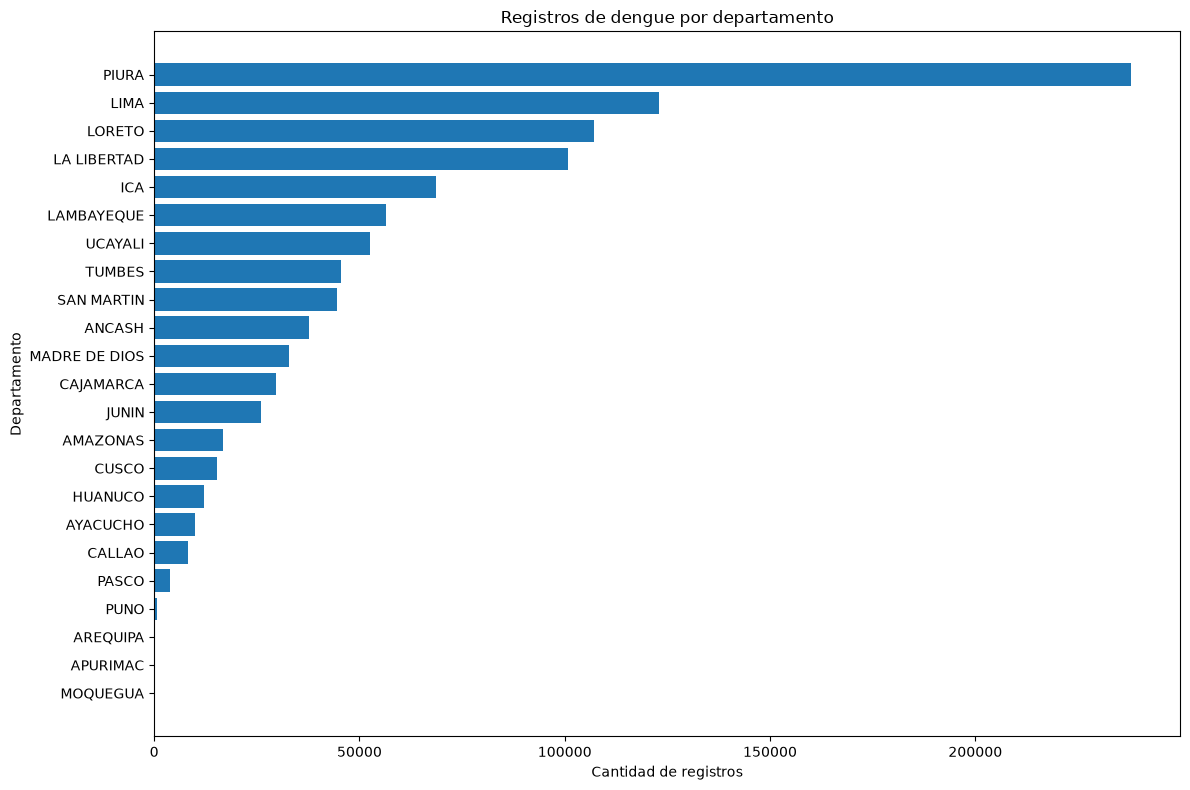

In [10]:
casos_departamento = (
    df.groupby("departamento")
    .size()
    .reset_index(name="registros")
    .sort_values("registros", ascending=False)
)

display(casos_departamento)

plt.figure(figsize=(12, 8))

plt.barh(
    casos_departamento["departamento"],
    casos_departamento["registros"]
)

plt.gca().invert_yaxis()

plt.title("Registros de dengue por departamento")
plt.xlabel("Cantidad de registros")
plt.ylabel("Departamento")

plt.tight_layout()
plt.show()

## 7. Analizar específicamente Ayacucho

Registros de Ayacucho: 9946

Registros por año:


,ano,registros
0,2013,1
1,2015,268
2,2016,2638
3,2017,1657
4,2018,202
5,2019,95
6,2020,1583
7,2021,1663
8,2022,782
9,2023,695



Registros por provincia:


,provincia,registros
3,LA MAR,5723
2,HUANTA,4195
1,HUAMANGA,21
5,PARINACOCHAS,2
7,SUCRE,2
0,CANGALLO,1
4,LUCANAS,1
6,PAUCAR DEL SARA SARA,1


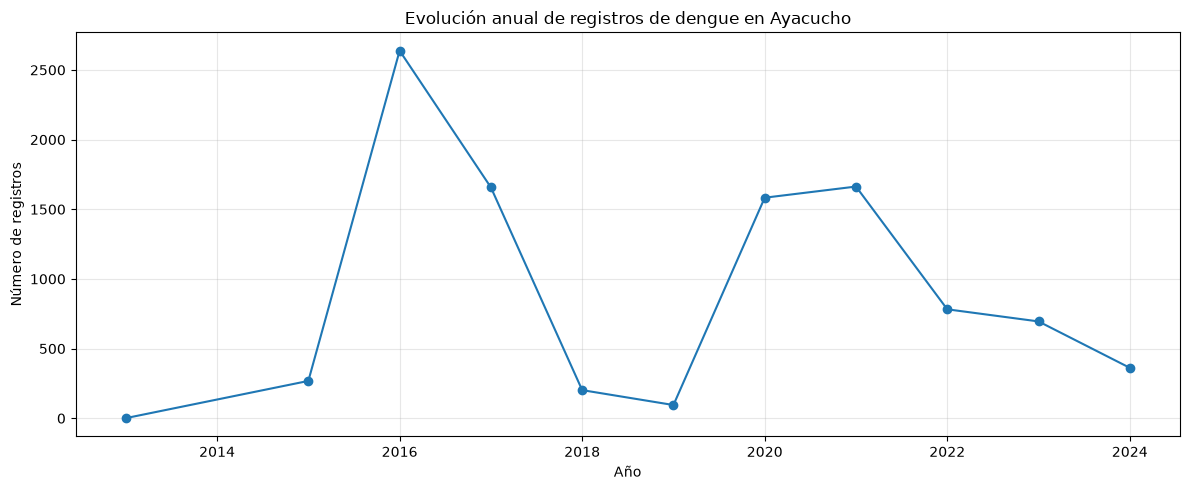

In [11]:
ayacucho = df[
    df["departamento"]
    .astype("string")
    .str.strip()
    .str.upper() == "AYACUCHO"
].copy()

print("Registros de Ayacucho:", len(ayacucho))

print("\nRegistros por año:")
display(
    ayacucho.groupby("ano")
    .size()
    .reset_index(name="registros")
)

print("\nRegistros por provincia:")
display(
    ayacucho.groupby("provincia")
    .size()
    .reset_index(name="registros")
    .sort_values("registros", ascending=False)
)

plt.figure(figsize=(12, 5))

ayacucho.groupby("ano").size().plot(
    kind="line",
    marker="o"
)

plt.title("Evolución anual de registros de dengue en Ayacucho")
plt.xlabel("Año")
plt.ylabel("Número de registros")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()